<a href="https://colab.research.google.com/github/yudiuwu/IA-carol/blob/main/IA_CAROL_CEGO_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 8 — Preparação dos dados com Python

**Disciplina:** Fundamentos de Inteligência Artificial  
**Curso:** Análise e Desenvolvimento de Sistemas  


---

**Nome do Aluno:** Yudi Hartmann
**Projeto:** Blind Infinity
**Data:** 17/09/2026  

---



Dowload pandas


In [ ]:
# Importação das bibliotecas essenciais para manipulação e análise de dados
import pandas as pd  # Convenção universal de apelido para o Pandas
import numpy as np   # Convenção universal de apelido para o NumPy

# Importações do Scikit-Learn (a biblioteca padrão de IA em Python)
from sklearn.model_selection import train_test_split  # Para separar dados de treino e teste
from sklearn.impute import SimpleImputer              # Para tratar valores ausentes
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # Para escala e codificação de texto
from sklearn.compose import ColumnTransformer          # Para aplicar transformações em colunas específicas
from sklearn.pipeline import Pipeline                 # Para encadear as etapas do fluxo de forma segura

### Instalação de pacotes
O Google Colab já vem com quase todas as bibliotecas de ciência de dados pré-instaladas por padrão. Caso você precise rodar este código localmente em seu próprio computador, execute a linha de instalação abaixo.

In [ ]:
# Linha comentada de instalação caso necessite configurar um ambiente local
# !pip install pandas numpy scikit-learn

### Leitura de CSV

In [ ]:
# Exemplo conceitual de como carregar um arquivo com os parâmetros brasileiros corretos
# df = pd.read_csv("caminho_do_arquivo.csv", sep=";", encoding="latin-1", decimal=",", parse_dates=["data_cadastro"])

### Regra de Ouro: Nunca altere a base original diretamente!

Sempre que carregar um arquivo, guarde uma cópia intacta dele em outra variável. Se você cometer um erro grave de limpeza no meio do caminho, poderá recuperar o DataFrame original sem precisar ler todo o arquivo do disco novamente.

In [ ]:
# Exemplo de preservação do estado original da base de dados
# df_original = df.copy()  # Criamos uma cópia isolada na memória RAM

### Mais algumas instalções

In [1]:

!pip install -q tensorflow-datasets

import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)


### Base de EMNIST

In [3]:
!pip install -q importlib_resources

(ds_train, ds_test), ds_info = tfds.load(
    "emnist/letters",
    split=["train", "test"],
    as_supervised=True,
    with_info=True
)

print(ds_info)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/letters/incomplete.C3WI1C_3.1.0/emnist-train.tfrecord-[0-9][0-9][0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/letters/incomplete.C3WI1C_3.1.0/emnist-test.tfrecord-[0-9][0-9][0-9…

Dataset emnist downloaded and prepared to /root/tensorflow_datasets/emnist/letters/3.1.0. Subsequent calls will reuse this data.
tfds.core.DatasetInfo(
    name='emnist',
    full_name='emnist/letters/3.1.0',
    description="""
    The EMNIST dataset is a set of handwritten character digits derived from the NIST Special Database 19 and converted to a 28x28 pixel image format and dataset structure that directly matches the MNIST dataset.
    
    Note: Like the original EMNIST data, images provided here are inverted horizontally and rotated 90 anti-clockwise. You can use `tf.transpose` within `ds.map` to convert the images to a human-friendlier format.
    """,
    config_description="""
    EMNIST Letters
    """,
    homepage='https://www.nist.gov/itl/products-and-services/emnist-dataset',
    data_dir='/root/tensorflow_datasets/emnist/letters/3.1.0',
    file_format=tfrecord,
    download_size=535.73 MiB,
    dataset_size=44.14 MiB,
    features=FeaturesDict({
        'image': Image


### Visualização de Dados.

codigo que retorna uma imagem em pixels, para compreender como são as imagens analisadas


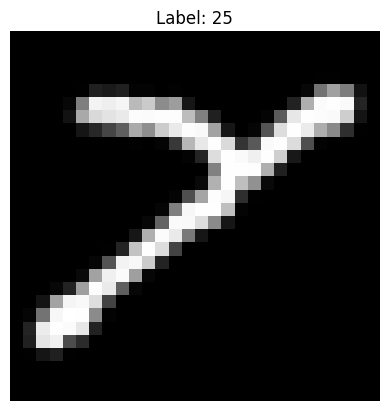

['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36']


In [6]:

for image, label in ds_train.take(1):
    plt.imshow(image.numpy().squeeze(), cmap="gray")
    plt.title(f"Label: {label.numpy()}")
    plt.axis("off")
    plt.show()

print(ds_info.features["label"].names)


#### 3. Tratamento é transformação dos dados

Transform os dados de um jeito que deixa legível para o knn, juntamos o treinamento e o teste ja que eles passam pela mesma conversão de dados

In [9]:

# Dados de treinamento
X_train = []
y_train = []

for image, label in ds_train:
    X_train.append(image.numpy())
    y_train.append(label.numpy())

X_train = np.array(X_train)
y_train = np.array(y_train)

# Dados de teste
X_test = []
y_test = []

for image, label in ds_test:
    X_test.append(image.numpy())
    y_test.append(label.numpy())

X_test = np.array(X_test)
y_test = np.array(y_test)

# Normalização e transformação
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train = X_train.reshape(X_train.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)


Treino: (88800, 784)
Teste: (14800, 784)


#### 4. Verificação dos valores invalidos

In [10]:

print("NaN no treino:", np.isnan(X_train).sum())
print("Infinitos no treino:", np.isinf(X_train).sum())

print("NaN no teste:", np.isnan(X_test).sum())
print("Infinitos no teste:", np.isinf(X_test).sum())

unique, counts = np.unique(y_train, return_counts=True)

for classe, quantidade in zip(unique, counts):
    print(f"Classe {classe}: {quantidade} imagens")


NaN no treino: 0
Infinitos no treino: 0
NaN no teste: 0
Infinitos no teste: 0
Classe 1: 3396 imagens
Classe 2: 3396 imagens
Classe 3: 3419 imagens
Classe 4: 3398 imagens
Classe 5: 3437 imagens
Classe 6: 3394 imagens
Classe 7: 3385 imagens
Classe 8: 3424 imagens
Classe 9: 3428 imagens
Classe 10: 3402 imagens
Classe 11: 3438 imagens
Classe 12: 3415 imagens
Classe 13: 3402 imagens
Classe 14: 3365 imagens
Classe 15: 3408 imagens
Classe 16: 3430 imagens
Classe 17: 3435 imagens
Classe 18: 3419 imagens
Classe 19: 3392 imagens
Classe 20: 3436 imagens
Classe 21: 3419 imagens
Classe 22: 3422 imagens
Classe 23: 3423 imagens
Classe 24: 3437 imagens
Classe 25: 3453 imagens
Classe 26: 3427 imagens


#### 5. Identificação de dados frequentes é quantidade

Identifica a quantidade de categorias, classe que mais aparece e a frequência

In [11]:

unique, counts = np.unique(y_train, return_counts=True)

print("Quantidade de categorias:", len(unique))

indice = np.argmax(counts)

print("Classe mais frequente:", unique[indice])
print("Frequência:", counts[indice])


Quantidade de categorias: 26
Classe mais frequente: 25
Frequência: 3453


#### 6. Valores Ausentes
Soma a quantidade de células vazias em cada uma das variáveis da tabela.

In [12]:

print("Valores ausentes no treinamento:", np.isnan(X_train).sum())
print("Valores ausentes no teste:", np.isnan(X_test).sum())


Valores ausentes no treinamento: 0
Valores ausentes no teste: 0


#### 7. Contagem de Imagens duplicatas

In [13]:

# Verificar imagens duplicadas no treinamento
dados_treino = np.column_stack((X_train, y_train))

duplicatas = len(dados_treino) - len(np.unique(dados_treino, axis=0))

print("Registros duplicados no treinamento:", duplicatas)


Registros duplicados no treinamento: 2


#### 8. Treinamento do knn

In [14]:

knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(X_train, y_train)

print("Modelo KNN treinado!")


Modelo KNN treinado!


#### 9. Previsão do modelo de teste, tentar fazer ele reconhecer a imagens do treino

In [15]:


y_pred = knn.predict(X_test)

print("Previsões realizadas!")


Previsões realizadas!


### 10.Avaliação do modelo, calcular o desempenho do knn é visualizar os erros

Acurácia: 84.19%
              precision    recall  f1-score   support

           1       0.79      0.85      0.82       800
           2       0.93      0.83      0.88       800
           3       0.83      0.95      0.89       800
           4       0.94      0.83      0.88       800
           5       0.90      0.89      0.90       800
           6       0.92      0.83      0.88       800
           7       0.85      0.66      0.74       800
           8       0.85      0.90      0.87       800
           9       0.64      0.71      0.67       800
          10       0.92      0.88      0.90       800
          11       0.95      0.85      0.90       800
          12       0.65      0.70      0.68       800
          13       0.98      0.94      0.96       800
          14       0.90      0.91      0.90       800
          15       0.80      0.97      0.88       800
          16       0.88      0.93      0.90       800
          17       0.82      0.64      0.72       800
          

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


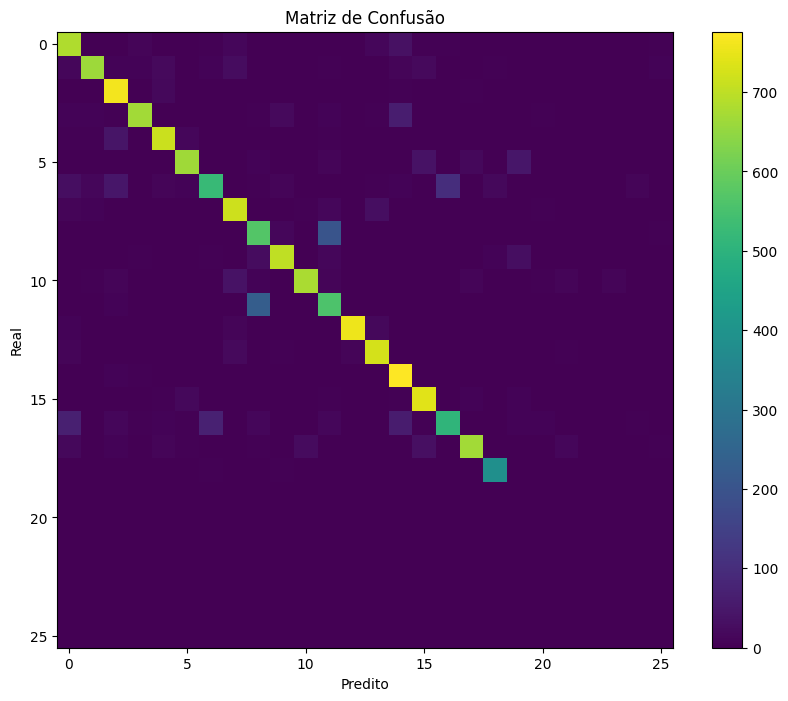

In [16]:

accuracy_knn = accuracy_score(y_test, y_pred)

print(f"Acurácia: {accuracy_knn:.2%}")

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
plt.imshow(cm)
plt.xlabel("Predito")
plt.ylabel("Real")
plt.title("Matriz de Confusão")
plt.colorbar()
plt.show()


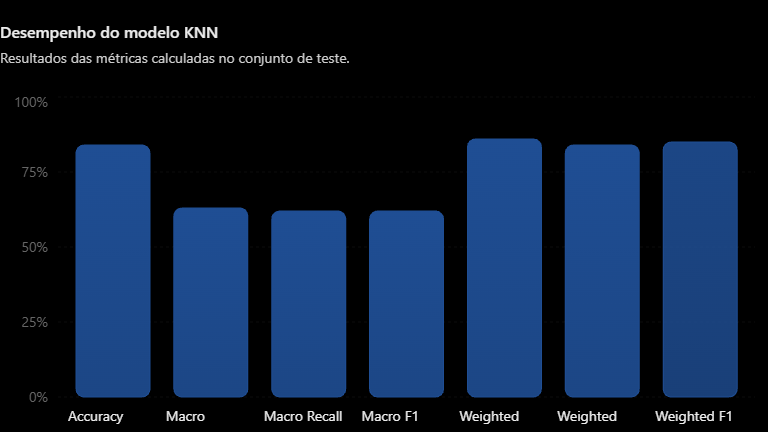

### 11. Comparação com o baseline

Baseline: 0.00%
KNN: 84.19%


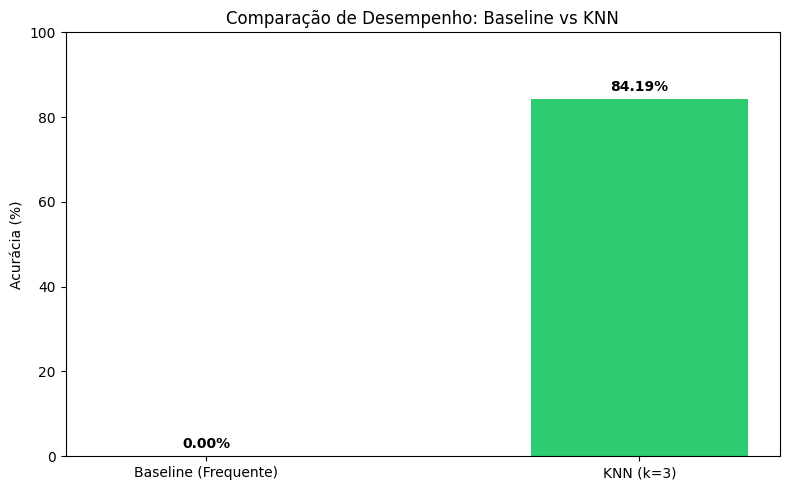

In [18]:
baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)

y_pred_baseline = baseline.predict(X_test)

accuracy_baseline = accuracy_score(
    y_test,
    y_pred_baseline
)

print(f"Baseline: {accuracy_baseline:.2%}")
print(f"KNN: {accuracy_knn:.2%}")

# Gráfico de comparação
modelos = ['Baseline (Frequente)', 'KNN (k=3)']
acuracias = [accuracy_baseline * 100, accuracy_knn * 100]

plt.figure(figsize=(8, 5))
plt.bar(modelos, acuracias, color=['#e74c3c', '#2ecc71'], width=0.5)
plt.ylabel('Acurácia (%)')
plt.title('Comparação de Desempenho: Baseline vs KNN')
plt.ylim(0, 100)

# Adicionando os valores sobre as barras
for i, v in enumerate(acuracias):
    plt.text(i, v + 2, f"{v:.2f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

### 12. Exemplos de erro

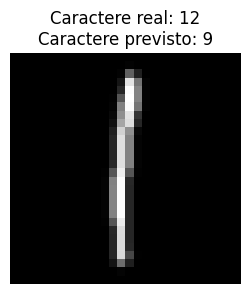

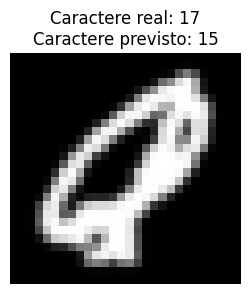

In [20]:
# Encontrar exemplos em que o modelo errou
erros = np.where(y_test != y_pred)[0]

# Mostrar 2 exemplos de erros com a orientação corrigida (.T)
for i in erros[:2]:
    plt.figure(figsize=(3, 3))

    # Transpomos a matriz 28x28 para corrigir a rotação/espelhamento
    imagem_corrigida = X_test[i].reshape(28, 28).T

    plt.imshow(imagem_corrigida, cmap="gray")

    plt.title(
        f"Caractere real: {y_test[i]}\n"
        f"Caractere previsto: {y_pred[i]}"
    )

    plt.axis("off")
    plt.show()

### 13. Visualização das previsões é salvamento


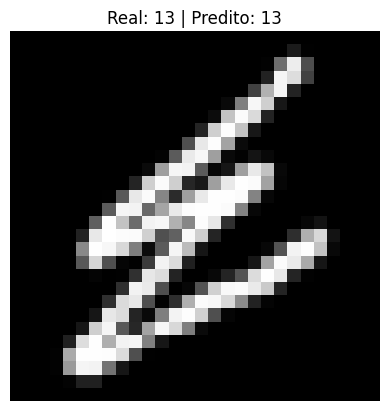

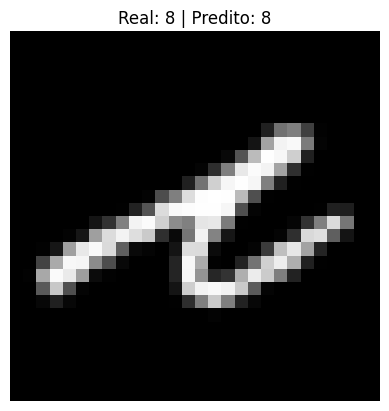

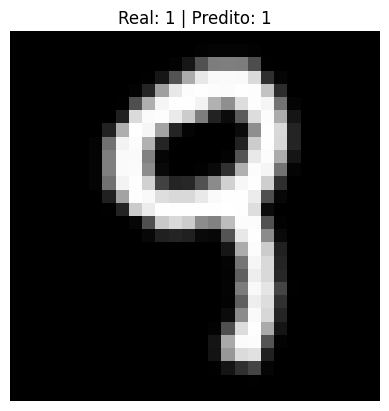

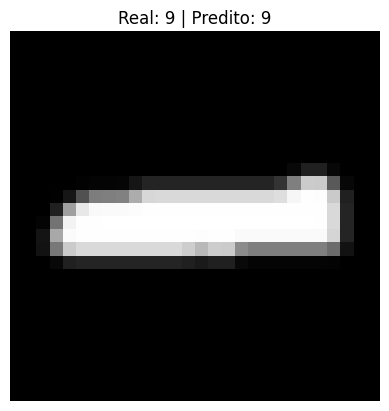

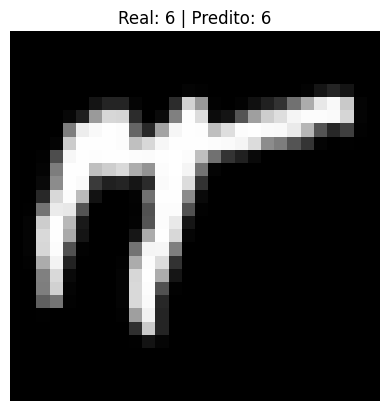

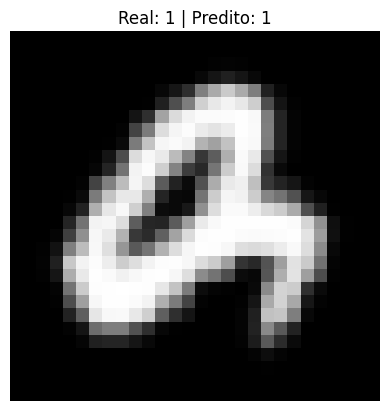

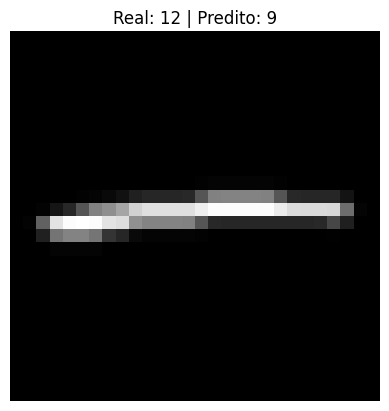

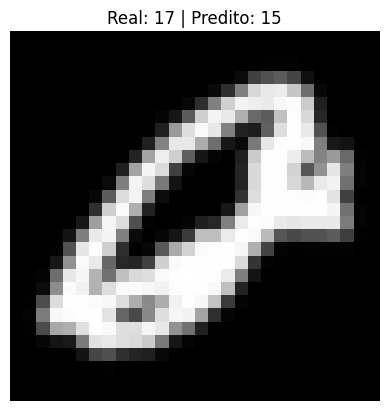

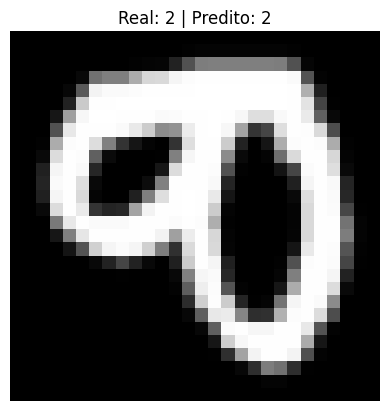

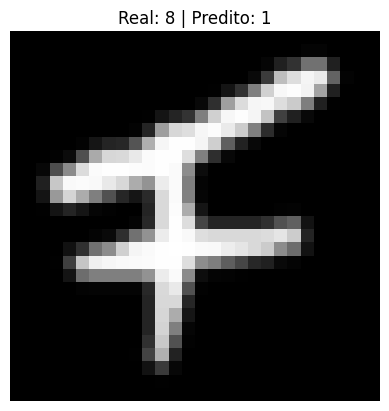

Base tratada salva com sucesso!


In [21]:

# Mostrar 10 previsões
for i in range(10):
    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")
    plt.title(f"Real: {y_test[i]} | Predito: {y_pred[i]}")
    plt.axis("off")
    plt.show()

# Salvar os dados tratados
np.savez(
    "emnist_letters_tratado.npz",
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test
)

print("Base tratada salva com sucesso!")


## 14. CNN REDE NEURAL


Total de imagens: 103600
Classes encontradas: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26]
Imagens para treino: (82880, 784)
Imagens para teste: (20720, 784)

===== COMPARAÇÃO DOS MODELOS =====
Baseline: 4.09%
KNN:      82.05%
MLP:      87.45%

===== TREINO E TESTE DA MLP =====
Acurácia no treino: 94.09%
Acurácia no teste:  87.45%
Épocas executadas:  24

===== RELATÓRIO KNN =====
              precision    recall  f1-score   support

           1       0.72      0.81      0.76       839
           2       0.85      0.80      0.82       839
           3       0.78      0.92      0.84       844
           4       0.85      0.83      0.84       840
           5       0.86      0.87      0.86       847
           6       0.82      0.86      0.84       839
           7       0.76      0.62      0.69       837
           8       0.79      0.86      0.82       845
           9       0.61      0.69      0.65       846
          10       0.83      0.86      0

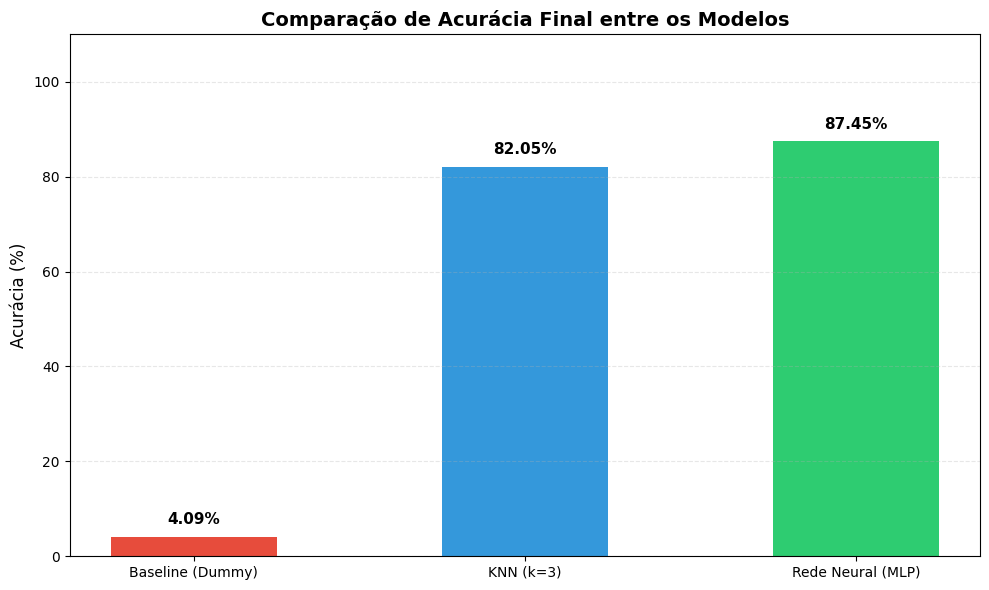

In [23]:
# IMPORTAÇÕES
import numpy as np
import warnings
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report
)

# 1. REUNIR OS DADOS
X = np.concatenate((X_train, X_test), axis=0)
y = np.concatenate((y_train, y_test), axis=0)

print("Total de imagens:", len(X))
print("Classes encontradas:", np.unique(y))

# 2. CRIAR UMA ÚNICA DIVISÃO PARA TODOS OS MODELOS
X_train_exp, X_test_exp, y_train_exp, y_test_exp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Imagens para treino:", X_train_exp.shape)
print("Imagens para teste:", X_test_exp.shape)

# 3. MODELO CLÁSSICO: KNN
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=3)
)

knn.fit(X_train_exp, y_train_exp)

pred_knn = knn.predict(X_test_exp)

# 4. REDE NEURAL: MLP
mlp = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        max_iter=30,
        early_stopping=True,
        random_state=42
    )
)

mlp.fit(X_train_exp, y_train_exp)

pred_mlp = mlp.predict(X_test_exp)

# 5. BASELINE
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train_exp, y_train_exp)

pred_baseline = baseline.predict(X_test_exp)

# 6. COMPARAR A ACURÁCIA
acc_knn = accuracy_score(y_test_exp, pred_knn)
acc_mlp = accuracy_score(y_test_exp, pred_mlp)
acc_baseline = accuracy_score(y_test_exp, pred_baseline)

print("\n===== COMPARAÇÃO DOS MODELOS =====")
print(f"Baseline: {acc_baseline:.2%}")
print(f"KNN:      {acc_knn:.2%}")
print(f"MLP:      {acc_mlp:.2%}")

# 7. DESEMPENHO DA REDE NO TREINO E NO TESTE
pred_mlp_treino = mlp.predict(X_train_exp)

acc_mlp_treino = accuracy_score(
    y_train_exp,
    pred_mlp_treino
)

print("\n===== TREINO E TESTE DA MLP =====")
print(f"Acurácia no treino: {acc_mlp_treino:.2%}")
print(f"Acurácia no teste:  {acc_mlp:.2%}")
print(f"Épocas executadas:  {mlp.named_steps['mlpclassifier'].n_iter_}")

# 8. RELATÓRIO DE CLASSIFICAÇÃO
print("\n===== RELATÓRIO KNN =====")
print(classification_report(y_test_exp, pred_knn))

print("\n===== RELATÓRIO MLP =====")
print(classification_report(y_test_exp, pred_mlp))

# 9. GRÁFICO COMPARATIVO DE ACURÁCIA
modelos = ['Baseline (Dummy)', 'KNN (k=3)', 'Rede Neural (MLP)']
acuracias = [acc_baseline * 100, acc_knn * 100, acc_mlp * 100]

plt.figure(figsize=(10, 6))
cores = ['#e74c3c', '#3498db', '#2ecc71']
barras = plt.bar(modelos, acuracias, color=cores, width=0.5)

plt.ylabel('Acurácia (%)', fontsize=12)
plt.title('Comparação de Acurácia Final entre os Modelos', fontsize=14, fontweight='bold')
plt.ylim(0, 110)
plt.grid(axis='y', linestyle='--', alpha=0.3)

# Adicionar os valores exatos sobre as barras
for barra in barras:
    yval = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width()/2.0,
        yval + 2,
        f"{yval:.2f}%",
        ha='center',
        va='bottom',
        fontweight='bold',
        fontsize=11
    )

plt.tight_layout()
plt.show()

essa comparação usa uma nova divisão aleatória de 80% para treino e 20% para teste, reunindo os dois conjuntos originais do EMNIST. Portanto, os resultados podem ser diferentes dos 84,19% obtidos anteriormente pelo KNN.